# 03 — Regression: predicting the Apnea-Hypopnea Index (IAH)

**Input:** `../data/processed/OSA_DB_UPM.xlsx` (637 patients, output of `src/01_data_preparation.py`)
**Output:** results tables in `../results/`, figures in `../figures/`

**Question:** how well can IAH be predicted from easily collected clinical variables (gender, age, weight, height, neck circumference, BMI)?

**Version 2 — what changed.** The first version evaluated the models on a single 80/20 train/test split. With 637 patients the test set has only 128 patients, and the score depends strongly on which patients fall in it (shown in Section 2). Following the professor's feedback, the evaluation now uses **resampling**:

| Method | What it does | Used for |
|---|---|---|
| **Nested repeated cross-validation** | outer loop: 5 folds × 5 repeats = 25 test folds, every patient is tested 5 times; inner loop: 5-fold `GridSearchCV` on the training part chooses the hyperparameters | main evaluation of all models |
| **Bootstrap confidence intervals** | resample the patients with replacement 2,000 times and recompute the metric | 95% confidence interval of each score, and of the difference between two models |
| **Bootstrap out-of-bag evaluation** | train on a bootstrap sample (637 patients drawn with replacement), test on the patients that were not drawn (≈ 37%), 200 times | independent cross-check of the cross-validation |

Each model is still tested with two targets: raw IAH, and log(1 + IAH) (the EDA showed that IAH is strongly right-skewed). Predictions are always converted back to IAH, so all errors are in events/hour.

*Run time: about 5 minutes.*

In [1]:
from pathlib import Path
from collections import Counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, KFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
DATA = Path("../data/processed/OSA_DB_UPM.xlsx")
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

def metrics(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred), "RMSE": root_mean_squared_error(y_true, pred),
            "R2": r2_score(y_true, pred)}

## 1. Data and features
- `Male` encodes gender as 0/1 (models need numbers).
- `BMI` is recomputed from weight and height (feature engineering).
- `strata` = IAH quintile of each patient. It is only used to build balanced splits: every fold receives the same mix of mild and severe patients (IAH is skewed, a purely random split could put most severe cases on one side).

In [2]:
df = pd.read_excel(DATA)
df["Male"] = (df["Gender"] == "hombre").astype(int)
df["BMI"] = df["Weight"] / (df["Height"] / 100) ** 2

FEATURES = ["Male", "Age", "Weight", "Height", "Cervical", "BMI"]
X = df[FEATURES]
y = df["IAH"]
strata = pd.qcut(y, q=5, labels=False)
n = len(y)
print(X.shape)
X.head()

(637, 6)


,Male,Age,Weight,Height,Cervical,BMI
0,1,56,119,174,48.0,39.305060
1,1,39,78,168,42.0,27.636054
2,1,32,80,173,40.0,26.729927
3,1,32,109,190,42.0,30.193906
4,1,39,86,169,42.0,30.110991


## 2. Why a single 80/20 split is not enough
Experiment: the same model (linear regression) is trained and tested on **200 different random 80/20 splits**. Only the random seed of the split changes. If one split were a reliable measure, the 200 scores would be almost identical.

The red line is the split of the first version of this notebook (seed 42).

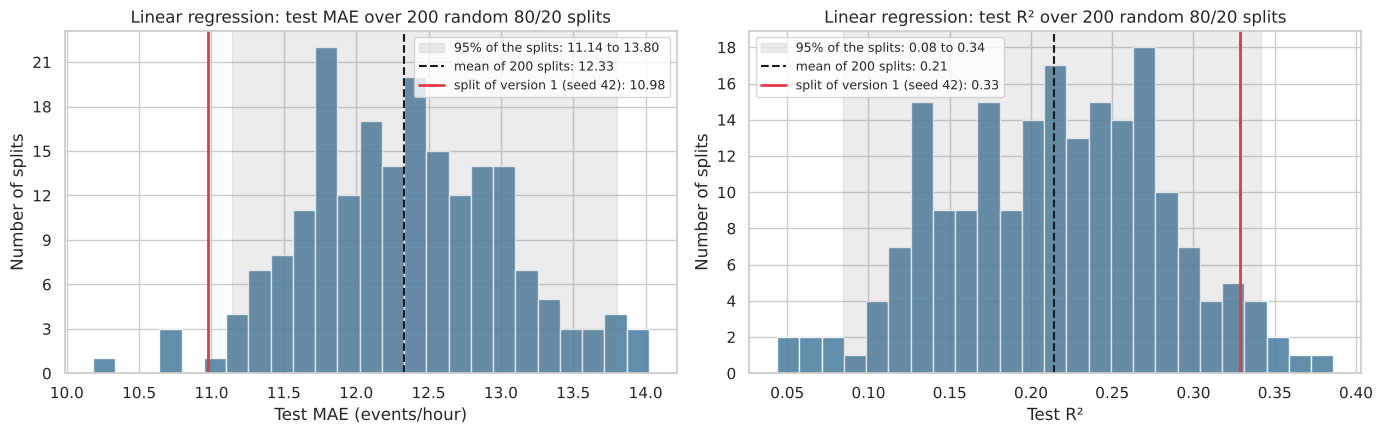

Version-1 split: better MAE than 98% of the splits, better R² than 95% of the splits


,MAE,RMSE,R2
mean,12.332,16.286,0.214
std,0.694,1.249,0.068
min,10.179,12.939,0.044
max,14.022,19.584,0.386


In [3]:
scaled = lambda m: Pipeline([("scale", StandardScaler()), ("model", m)])
plain = lambda m: Pipeline([("model", m)])

def one_split(seed):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=strata)
    model = scaled(LinearRegression()).fit(X_tr, y_tr)
    return metrics(y_te, model.predict(X_te))

splits = pd.DataFrame([one_split(s) for s in range(200)])
first = splits.loc[SEED]                        # the split used in version 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, unit in zip(axes, ["MAE", "R2"], [" (events/hour)", ""]):
    lo, hi = np.percentile(splits[m], [2.5, 97.5])
    ax.hist(splits[m], bins=25, color="#457b9d", alpha=0.85)
    ax.axvspan(lo, hi, color="grey", alpha=0.15, label=f"95% of the splits: {lo:.2f} to {hi:.2f}")
    ax.axvline(splits[m].mean(), color="k", ls="--", lw=1.5, label=f"mean of 200 splits: {splits[m].mean():.2f}")
    ax.axvline(first[m], color="#e63946", lw=2, label=f"split of version 1 (seed 42): {first[m]:.2f}")
    ax.set(xlabel=f"Test {m.replace('R2', 'R²')}{unit}", ylabel="Number of splits")
    ax.legend(fontsize=9); ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_title("Linear regression: test MAE over 200 random 80/20 splits")
axes[1].set_title("Linear regression: test R² over 200 random 80/20 splits")
plt.tight_layout(); plt.savefig(FIG / "reg_04_split_variability.png", dpi=200); plt.show()

print(f"Version-1 split: better MAE than {(splits.MAE > first.MAE).mean():.0%} of the splits, "
      f"better R² than {(splits.R2 < first.R2).mean():.0%} of the splits")
splits.describe().loc[["mean", "std", "min", "max"]].round(3)

## 3. Models and hyperparameters
Each model is a `Pipeline`. Models based on distances or coefficient sizes (linear, SVR, KNN) need standardised inputs, so a `StandardScaler` is included: it is fitted on the training part of each fold only, which avoids information leaking from the test fold.

| Model | Idea | Hyperparameters tuned |
|---|---|---|
| Baseline | always predicts the mean IAH | – |
| Linear regression | IAH = w0 + w1·x1 + … (least squares) | – |
| Ridge | linear + L2 penalty on weights (stable with correlated inputs) | alpha |
| Lasso | linear + L1 penalty (can set weights to 0 = variable selection) | alpha |
| Decision tree | if/then splits | max_depth, min_samples_leaf |
| Random Forest | average of many trees (lower variance) | max_depth, min_samples_leaf |
| XGBoost | trees added one by one to correct previous errors (boosting) | n_estimators, max_depth, learning_rate |
| SVR | kernel model, ignores errors smaller than epsilon | C, epsilon, gamma |
| KNN | mean IAH of the k most similar patients | n_neighbors |

For the log target, `TransformedTargetRegressor` trains on log(1 + IAH) and converts predictions back with exp(x) − 1.

In [4]:
MODELS = {
    "Baseline (mean)": (plain(DummyRegressor(strategy="mean")), {}),
    "Linear regression": (scaled(LinearRegression()), {}),
    "Ridge": (scaled(Ridge()), {"model__alpha": [0.1, 1, 10, 100]}),
    "Lasso": (scaled(Lasso(max_iter=10000)), {"model__alpha": [0.01, 0.1, 0.5, 1]}),
    "Decision tree": (plain(DecisionTreeRegressor(random_state=SEED)),
                      {"model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [10, 20, 40]}),
    "Random Forest": (plain(RandomForestRegressor(n_estimators=200, random_state=SEED)),
                      {"model__max_depth": [3, None], "model__min_samples_leaf": [5, 20]}),
    "XGBoost": (plain(XGBRegressor(random_state=SEED, n_jobs=1, subsample=0.8)),
                {"model__n_estimators": [100, 300], "model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1]}),
    "SVR": (scaled(SVR()), {"model__C": [1, 10, 30], "model__epsilon": [1, 5], "model__gamma": ["scale", 0.05]}),
    "KNN": (scaled(KNeighborsRegressor()), {"model__n_neighbors": [5, 15, 30, 50]}),
}
TARGETS = ["IAH", "log(1+IAH)"]

def with_target(pipe, grid, target):
    if target == "IAH":
        return clone(pipe), grid
    model = TransformedTargetRegressor(regressor=clone(pipe), func=np.log1p, inverse_func=np.expm1)
    return model, {f"regressor__{k}": v for k, v in grid.items()}

inner_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def build(name, target):
    """Model + its inner grid search (the hyperparameters are chosen on the training part only)."""
    est, grid = with_target(*MODELS[name], target)
    return GridSearchCV(est, grid, cv=inner_cv, scoring="neg_mean_absolute_error") if grid else est

## 4. Nested repeated cross-validation
- **Outer loop (evaluation):** 5 folds, repeated 5 times with different shuffles → 25 train/test pairs. Each time, 80% of the patients train the model and the other 20% test it. After one repeat every patient has been in a test fold exactly once.
- **Inner loop (tuning):** inside each outer training set, `GridSearchCV` (5 folds) tries all hyperparameter combinations and keeps the one with the lowest MAE.

The outer test fold is never seen by the grid search, so its score is not optimistic. All models use **the same 25 splits**, so they can be compared patient by patient.

For every model we keep the 25 fold scores and the **out-of-fold predictions**: 5 predictions per patient (one per repeat), each made by a model that never saw this patient.

In [5]:
N_SPLITS, N_REPEATS = 5, 5
outer = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(X, strata))

fold_rows, oof, fitted = [], {}, {}
for name in MODELS:
    for target in TARGETS:
        res = cross_validate(build(name, target), X, y, cv=outer, return_estimator=True, n_jobs=-1)
        P = np.zeros((N_REPEATS, n))
        for k, ((_, test), est) in enumerate(zip(outer, res["estimator"])):
            pred = est.predict(X.iloc[test])
            P[k // N_SPLITS, test] = pred
            fold_rows.append({"Model": name, "Target": target, "Repeat": k // N_SPLITS + 1, "Fold": k % N_SPLITS + 1,
                              **metrics(y.iloc[test], pred)})
        oof[(name, target)], fitted[(name, target)] = P, res["estimator"]

folds = pd.DataFrame(fold_rows)
folds.to_csv(RES / "regression_test_results.csv", index=False)       # one row per outer test fold
print(f"{len(folds)} test-fold scores = {len(oof)} models x {len(outer)} folds")

450 test-fold scores = 18 models x 25 folds


## 5. Results with bootstrap confidence intervals
For each model:
- **MAE, RMSE, R²:** mean ± standard deviation over the 25 test folds.
- **95% confidence interval (bootstrap):** each patient has an error (averaged over the 5 repeats). The 637 patients are resampled with replacement 2,000 times and the metric is recomputed each time; the interval contains 95% of these values. It answers: *how much would the score change with another sample of 637 patients?*
- **Gain vs baseline:** MAE of the baseline minus MAE of the model, computed on the same resampled patients (paired). If the interval does not contain 0, the model is really better than predicting the mean.

In [6]:
rng = np.random.default_rng(SEED)
BOOT = rng.integers(0, n, size=(2000, n))                      # 2,000 resamples of the patient indices
yv = y.values
sst = ((yv[BOOT] - yv[BOOT].mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
ci = lambda v: np.percentile(v, [2.5, 97.5])

def patient_errors(key):
    err = oof[key] - yv                                        # (5 repeats, 637 patients)
    return np.abs(err).mean(axis=0), (err ** 2).mean(axis=0)   # per patient: absolute and squared error

BASE = ("Baseline (mean)", "IAH")
ae_base = patient_errors(BASE)[0]
rows = []
for key in oof:
    f = folds[(folds.Model == key[0]) & (folds.Target == key[1])]
    ae, se = patient_errors(key)
    mae_ci, r2_ci, gain_ci = ci(ae[BOOT].mean(axis=1)), ci(1 - se[BOOT].sum(axis=1) / sst), ci((ae_base - ae)[BOOT].mean(axis=1))
    rows.append({"Model": key[0], "Target": key[1],
                 "MAE": f.MAE.mean(), "MAE std": f.MAE.std(), "MAE CI low": mae_ci[0], "MAE CI high": mae_ci[1],
                 "RMSE": f.RMSE.mean(), "RMSE std": f.RMSE.std(),
                 "R2": f.R2.mean(), "R2 std": f.R2.std(), "R2 CI low": r2_ci[0], "R2 CI high": r2_ci[1],
                 "MAE gain vs baseline": (ae_base - ae).mean(), "Gain CI low": gain_ci[0], "Gain CI high": gain_ci[1]})

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
results.to_csv(RES / "regression_cv_results.csv", index=False)

show = results[["Model", "Target"]].copy()
show["MAE (25 folds)"] = results["MAE"].map("{:.2f}".format) + " ± " + results["MAE std"].map("{:.2f}".format)
show["MAE 95% CI"] = results["MAE CI low"].map("{:.1f}".format) + " to " + results["MAE CI high"].map("{:.1f}".format)
show["RMSE"] = results["RMSE"].map("{:.2f}".format)
show["R² (25 folds)"] = results["R2"].map("{:.3f}".format) + " ± " + results["R2 std"].map("{:.3f}".format)
show["R² 95% CI"] = results["R2 CI low"].map("{:.2f}".format) + " to " + results["R2 CI high"].map("{:.2f}".format)
show["MAE gain vs baseline (95% CI)"] = (results["MAE gain vs baseline"].map("{:.2f}".format) + " (" +
                                         results["Gain CI low"].map("{:.2f}".format) + " to " + results["Gain CI high"].map("{:.2f}".format) + ")")
show

,Model,Target,MAE (25 folds),MAE 95% CI,RMSE,R² (25 folds),R² 95% CI,MAE gain vs baseline (95% CI)
0,SVR,IAH,11.97 ± 0.63,11.1 to 12.9,16.86,0.171 ± 0.059,0.11 to 0.23,2.54 (1.92 to 3.12)
1,Ridge,log(1+IAH),11.98 ± 0.58,11.0 to 13.0,17.63,0.094 ± 0.058,0.02 to 0.17,2.53 (1.86 to 3.18)
2,Lasso,log(1+IAH),11.99 ± 0.58,11.0 to 13.0,17.66,0.091 ± 0.056,0.02 to 0.17,2.52 (1.84 to 3.19)
3,Linear regression,log(1+IAH),11.99 ± 0.60,11.0 to 13.0,17.60,0.096 ± 0.063,0.02 to 0.17,2.52 (1.82 to 3.19)
4,Random Forest,log(1+IAH),12.08 ± 0.65,11.1 to 13.1,17.44,0.115 ± 0.047,0.05 to 0.17,2.43 (1.81 to 3.04)
5,XGBoost,log(1+IAH),12.08 ± 0.66,11.1 to 13.1,17.56,0.102 ± 0.050,0.04 to 0.16,2.43 (1.82 to 3.02)
6,SVR,log(1+IAH),12.14 ± 0.63,11.2 to 13.2,17.99,0.058 ± 0.047,-0.00 to 0.12,2.37 (1.74 to 2.97)
7,KNN,log(1+IAH),12.27 ± 0.70,11.3 to 13.3,17.78,0.079 ± 0.058,0.02 to 0.14,2.24 (1.62 to 2.81)
8,Decision tree,log(1+IAH),12.31 ± 0.72,11.4 to 13.3,17.60,0.097 ± 0.061,0.03 to 0.16,2.20 (1.58 to 2.81)
9,XGBoost,IAH,12.32 ± 0.76,11.5 to 13.2,16.37,0.219 ± 0.053,0.15 to 0.28,2.19 (1.57 to 2.78)


## 6. Comparison of the models
Each box shows the 25 test-fold scores of one model. Overlapping boxes mean that the difference between two models is smaller than the variation caused by the split.

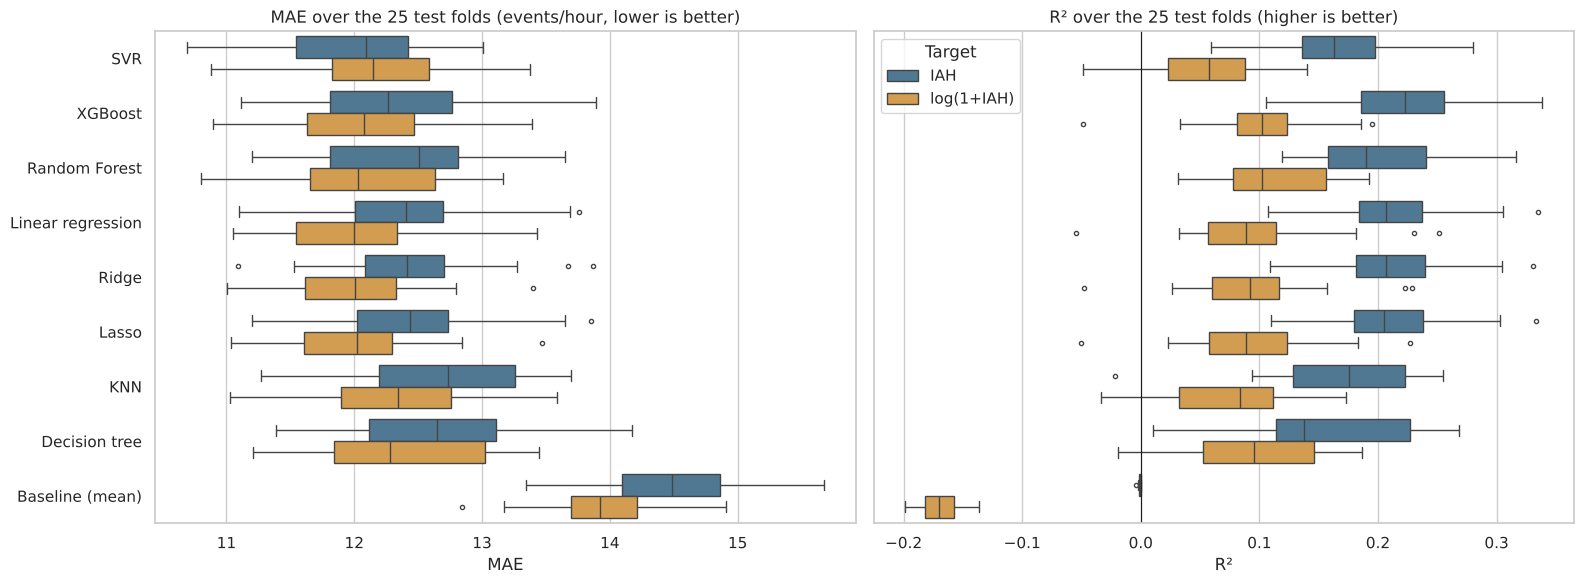

In [7]:
order = results[results.Target == "IAH"].sort_values("MAE")["Model"].tolist()
pal = {"IAH": "#457b9d", "log(1+IAH)": "#e9a03b"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, metric in zip(axes, ["MAE", "R2"]):
    sns.boxplot(data=folds, y="Model", x=metric, hue="Target", order=order, palette=pal, ax=ax,
                fliersize=3, linewidth=1)
    ax.set_ylabel("")
axes[0].set(title="MAE over the 25 test folds (events/hour, lower is better)", xlabel="MAE")
axes[1].set(title="R² over the 25 test folds (higher is better)", xlabel="R²")
axes[1].axvline(0, color="k", lw=0.8)
axes[0].get_legend().remove(); axes[1].legend(title="Target", loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "reg_01_model_comparison.png", dpi=200); plt.show()

**Is a complex model better than plain linear regression?** Paired bootstrap of the MAE difference (linear regression on the same target minus the model). A positive value means the model is better; if the interval contains 0, the difference is not significant.

In [8]:
rows = []
for key in oof:
    if key[0] in ("Baseline (mean)", "Linear regression"):
        continue
    d = patient_errors(("Linear regression", key[1]))[0] - patient_errors(key)[0]
    lo, hi = ci(d[BOOT].mean(axis=1))
    rows.append({"Model": key[0], "Target": key[1], "MAE gain vs linear regression": d.mean(),
                 "CI low": lo, "CI high": hi, "Significant": "yes" if lo > 0 or hi < 0 else "no"})
vs_linear = pd.DataFrame(rows).sort_values("MAE gain vs linear regression", ascending=False).reset_index(drop=True)
vs_linear.round(2)

,Model,Target,MAE gain vs linear regression,CI low,CI high,Significant
0,SVR,IAH,0.44,0.13,0.76,yes
1,XGBoost,IAH,0.08,-0.17,0.36,no
2,Ridge,log(1+IAH),0.02,-0.08,0.11,no
3,Lasso,log(1+IAH),0.00,-0.09,0.10,no
4,Random Forest,IAH,0.00,-0.25,0.28,no
5,Ridge,IAH,-0.02,-0.04,0.01,no
6,Lasso,IAH,-0.02,-0.06,0.02,no
7,Random Forest,log(1+IAH),-0.08,-0.42,0.25,no
8,XGBoost,log(1+IAH),-0.09,-0.41,0.23,no
9,SVR,log(1+IAH),-0.15,-0.48,0.15,no


## 7. Best model: predictions for all patients
The best model is the one with the lowest mean MAE. Each point is one patient; the prediction is the mean of its 5 out-of-fold predictions (models that never saw this patient). The dotted lines are the clinical thresholds IAH = 10 and IAH = 30.

Best model (lowest mean MAE): SVR on IAH
Hyperparameters chosen by the inner grid search in the 25 outer folds:
  14 / 25  {'C': 10, 'epsilon': 5, 'gamma': 0.05}
   5 / 25  {'C': 10, 'epsilon': 1, 'gamma': 0.05}
   3 / 25  {'C': 30, 'epsilon': 5, 'gamma': 0.05}
   2 / 25  {'C': 30, 'epsilon': 1, 'gamma': 0.05}
   1 / 25  {'C': 30, 'epsilon': 1, 'gamma': 'scale'}


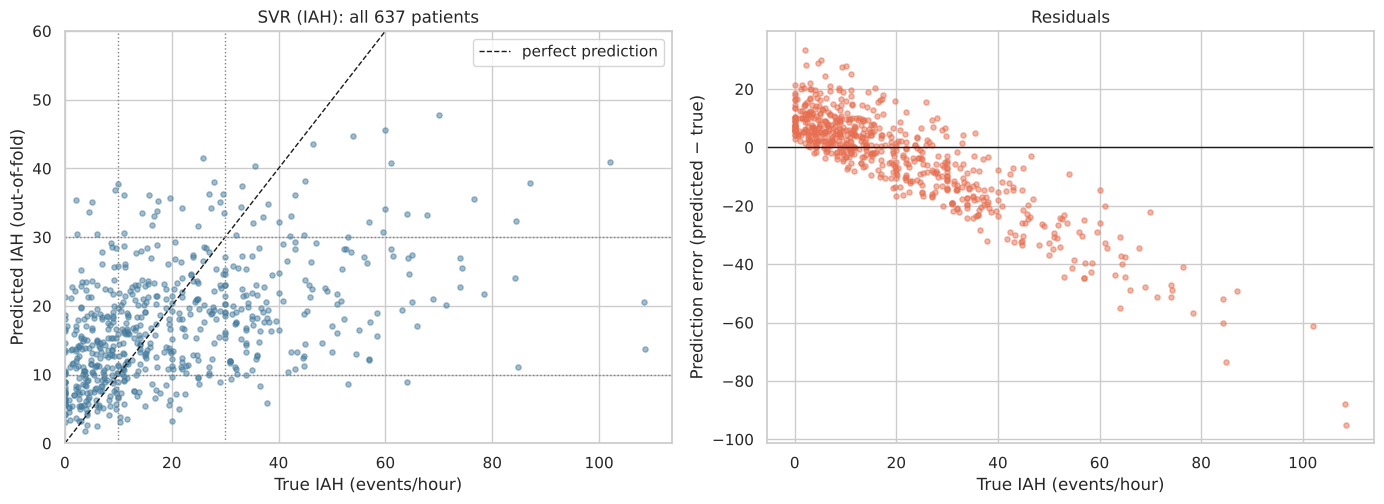

,Patients,Mean true IAH,Mean predicted IAH,MAE
Group,,,,
Healthy (IAH ≤ 10),242,4.8,12.8,8.4
Intermediate,229,18.4,18.0,6.7
Severe (IAH ≥ 30),166,45.9,21.9,24.2


In [9]:
best_key = tuple(results.iloc[0][["Model", "Target"]])
best_name, best_target = best_key
pred = oof[best_key].mean(axis=0)
print(f"Best model (lowest mean MAE): {best_name} on {best_target}")
print("Hyperparameters chosen by the inner grid search in the 25 outer folds:")
chosen = Counter(str({k.split('__')[-1]: v for k, v in e.best_params_.items()})
                 for e in fitted[best_key] if hasattr(e, "best_params_"))
for params, count in chosen.most_common():
    print(f"  {count:2d} / 25  {params}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].scatter(y, pred, s=14, alpha=0.5, color="#457b9d")
lim = [0, y.max() + 5]
axes[0].plot(lim, lim, "k--", lw=1, label="perfect prediction")
for t in (10, 30):
    axes[0].axvline(t, color="grey", ls=":", lw=1); axes[0].axhline(t, color="grey", ls=":", lw=1)
axes[0].set(xlim=lim, ylim=[0, max(pred.max() + 5, 60)], xlabel="True IAH (events/hour)", ylabel="Predicted IAH (out-of-fold)",
            title=f"{best_name} ({best_target}): all {n} patients")
axes[0].legend()
axes[1].scatter(y, pred - y, s=14, alpha=0.5, color="#e76f51")
axes[1].axhline(0, color="k", lw=1)
axes[1].set(xlabel="True IAH (events/hour)", ylabel="Prediction error (predicted − true)", title="Residuals")
plt.tight_layout(); plt.savefig(FIG / "reg_02_best_model_test.png", dpi=200); plt.show()

groups = np.where(y <= 10, "Healthy (IAH ≤ 10)", np.where(y >= 30, "Severe (IAH ≥ 30)", "Intermediate"))
by_group = pd.DataFrame({"Group": groups, "True IAH": y, "Predicted IAH": pred, "Absolute error": np.abs(pred - y)})
by_group.groupby("Group").agg(Patients=("True IAH", "size"), **{"Mean true IAH": ("True IAH", "mean"),
    "Mean predicted IAH": ("Predicted IAH", "mean"), "MAE": ("Absolute error", "mean")}).round(1)

## 8. Interpretation: which variables matter?
**a) Linear models.** With standardised inputs, each coefficient is the change in predicted IAH for +1 standard deviation of the variable. The table gives the mean ± standard deviation of each coefficient over the 25 outer training sets: a large standard deviation means the coefficient is unstable (expected for the correlated inputs Weight, Height and BMI).

In [10]:
def coefs(name):
    W = np.array([(e.best_estimator_ if hasattr(e, "best_estimator_") else e).named_steps["model"].coef_
                  for e in fitted[(name, "IAH")]])
    return [f"{m:.2f} ± {s:.2f}" for m, s in zip(W.mean(axis=0), W.std(axis=0))]

pd.DataFrame({name: coefs(name) for name in ["Linear regression", "Ridge", "Lasso"]}, index=FEATURES)

,Linear regression,Ridge,Lasso
Male,0.67 ± 0.60,0.60 ± 0.59,0.55 ± 0.58
Age,2.67 ± 0.28,2.64 ± 0.29,2.62 ± 0.33
Weight,20.41 ± 4.92,16.57 ± 6.06,15.47 ± 7.17
Height,-10.36 ± 2.42,-8.27 ± 3.09,-7.64 ± 3.74
Cervical,4.36 ± 0.71,4.41 ± 0.73,4.43 ± 0.69
BMI,-13.56 ± 4.37,-10.18 ± 5.41,-9.23 ± 6.33


**b) Permutation importance (best model).** In each of the 25 test folds, one variable at a time is shuffled and we measure how much the MAE gets worse: the larger the increase, the more the model relies on that variable. Each box shows the 25 folds.

*Caution:* when two variables carry the same information (Weight and BMI), shuffling one of them hurts less because the other is still there. Their individual importance is therefore underestimated.

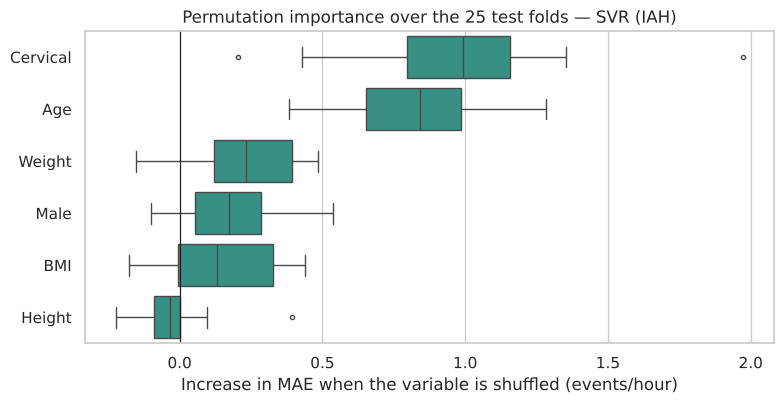

,mean,std
Cervical,0.964,0.359
Age,0.824,0.218
Weight,0.214,0.196
Male,0.200,0.179
BMI,0.152,0.176
Height,-0.031,0.116


In [11]:
imp = np.array([permutation_importance(est, X.iloc[test], y.iloc[test], scoring="neg_mean_absolute_error",
                                       n_repeats=10, random_state=SEED).importances_mean
                for (_, test), est in zip(outer, fitted[best_key])])
importance = pd.DataFrame(imp, columns=FEATURES)
order_f = importance.mean().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.boxplot(data=importance[order_f], orient="h", color="#2a9d8f", fliersize=3, linewidth=1, ax=ax)
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Increase in MAE when the variable is shuffled (events/hour)",
       title=f"Permutation importance over the 25 test folds — {best_name} ({best_target})")
plt.tight_layout(); plt.savefig(FIG / "reg_03_permutation_importance.png", dpi=200); plt.show()
importance[order_f].agg(["mean", "std"]).T.round(3)

## 9. Cross-check with the bootstrap (out-of-bag)
A different way to reuse a small dataset. One **bootstrap sample** = 637 patients drawn at random **with replacement**: some patients are drawn several times, and about 37% are never drawn. The model is trained on the bootstrap sample and tested on the patients that were not drawn (the **out-of-bag** patients). This is repeated 200 times.

Three models are checked: the baseline, linear regression, and the best model. The best model uses the hyperparameters most often chosen in Section 7 (no grid search here: a bootstrap sample contains duplicated patients, which would end up on both sides of the inner folds and bias the tuning).

*Expected difference with cross-validation:* a bootstrap sample contains only about 403 different patients, against 510 in a cross-validation training set, so the bootstrap is slightly pessimistic. Its test sets are larger (about 234 patients against 127), so its scores vary less.

In [12]:
B = 200
rng_b = np.random.default_rng(SEED)
samples = [rng_b.integers(0, n, n) for _ in range(B)]
print(f"Out-of-bag patients per sample: {np.mean([n - len(np.unique(s)) for s in samples]):.0f} on average "
      f"({np.mean([1 - len(np.unique(s)) / n for s in samples]):.1%})")

best_est, _ = with_target(*MODELS[best_name], best_target)
if chosen:
    top = next(e.best_params_ for e in fitted[best_key]
               if str({k.split('__')[-1]: v for k, v in e.best_params_.items()}) == chosen.most_common(1)[0][0])
    best_est.set_params(**top)
CHECK = {"Baseline (mean)": with_target(*MODELS["Baseline (mean)"], "IAH")[0],
         "Linear regression (IAH)": with_target(*MODELS["Linear regression"], "IAH")[0],
         f"{best_name} ({best_target})": best_est}
CV_KEYS = {"Baseline (mean)": BASE, "Linear regression (IAH)": ("Linear regression", "IAH"),
           f"{best_name} ({best_target})": best_key}

rows = []
for label, est in CHECK.items():
    for idx in samples:
        oob = np.setdiff1d(np.arange(n), idx)
        model = clone(est).fit(X.iloc[idx], y.iloc[idx])
        rows.append({"Model": label, "Method": "Bootstrap (200 out-of-bag sets)", **metrics(y.iloc[oob], model.predict(X.iloc[oob]))})
    f = folds[(folds.Model == CV_KEYS[label][0]) & (folds.Target == CV_KEYS[label][1])]
    rows += [{"Model": label, "Method": "Repeated CV (25 test folds)", "MAE": a, "RMSE": b, "R2": c}
             for a, b, c in zip(f.MAE, f.RMSE, f.R2)]
check = pd.DataFrame(rows)

summary = check.groupby(["Model", "Method"], sort=False)[["MAE", "RMSE", "R2"]].agg(["mean", "std"]).round(3)
summary.to_csv(RES / "regression_bootstrap_results.csv")
summary

Out-of-bag patients per sample: 234 on average (36.8%)


MAE         \
                                                           mean    std   
Model                   Method                                           
Baseline (mean)         Bootstrap (200 out-of-bag sets)  14.504  0.526   
                        Repeated CV (25 test folds)      14.510  0.613   
Linear regression (IAH) Bootstrap (200 out-of-bag sets)  12.494  0.520   
                        Repeated CV (25 test folds)      12.407  0.638   
SVR (IAH)               Bootstrap (200 out-of-bag sets)  12.058  0.592   
                        Repeated CV (25 test folds)      11.967  0.632   

                                                           RMSE            R2  \
                                                           mean    std   mean   
Model                   Method                                                  
Baseline (mean)         Bootstrap (200 out-of-bag sets)  18.506  0.978 -0.008   
                        Repeated CV (25 test folds)      18.544  1.272 -0.001   
Linear regression (IAH) Bootstrap (200 out-of-bag sets)  16.541  0.883  0.194   
                        Repeated CV (25 test folds)      16.434  1.072  0.212   
SVR (IAH)               Bootstrap (200 out-of-bag sets)  16.810  1.068  0.168   
                        Repeated CV (25 test folds)      16.858  1.215  0.171   

                                                                
                                                           std  
Model                   Method                                  
Baseline (mean)         Bootstrap (200 out-of-bag sets)  0.015  
                        Repeated CV (25 test folds)      0.001  
Linear regression (IAH) Bootstrap (200 out-of-bag sets)  0.044  
                        Repeated CV (25 test folds)      0.051  
SVR (IAH)               Bootstrap (200 out-of-bag sets)  0.044  
                        Repeated CV (25 test folds)      0.059

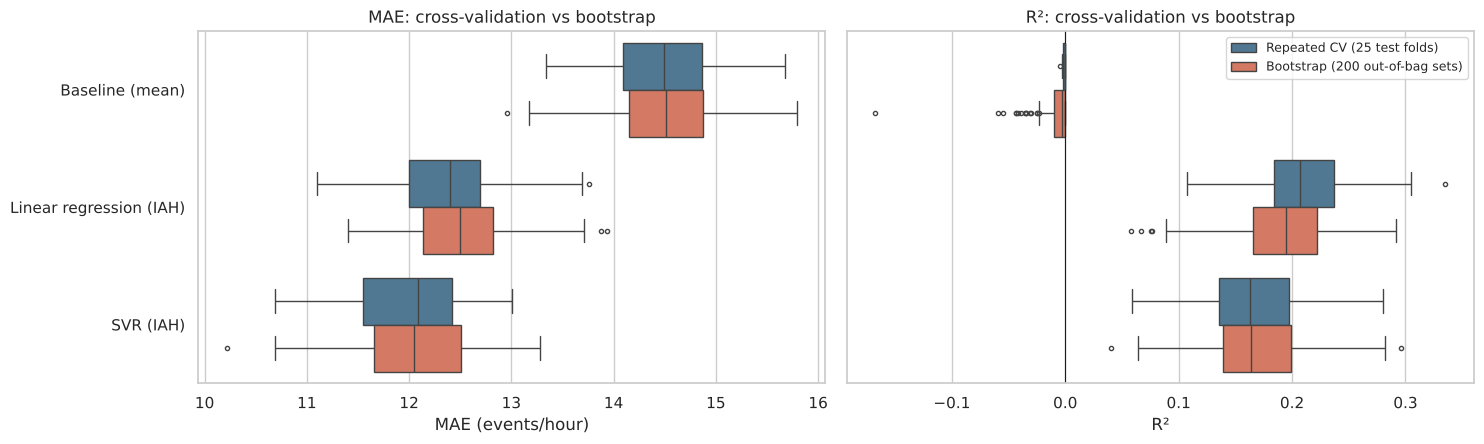

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
pal_m = {"Repeated CV (25 test folds)": "#457b9d", "Bootstrap (200 out-of-bag sets)": "#e76f51"}
for ax, metric in zip(axes, ["MAE", "R2"]):
    sns.boxplot(data=check, y="Model", x=metric, hue="Method", hue_order=list(pal_m), palette=pal_m, ax=ax,
                fliersize=3, linewidth=1)
    ax.set_ylabel("")
axes[0].set(title="MAE: cross-validation vs bootstrap", xlabel="MAE (events/hour)")
axes[1].set(title="R²: cross-validation vs bootstrap", xlabel="R²")
axes[1].axvline(0, color="k", lw=0.8)
axes[0].get_legend().remove(); axes[1].legend(title="", loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "reg_05_bootstrap_check.png", dpi=200); plt.show()

## 10. Conclusions

1. **A single 80/20 split is not a reliable measure on this dataset.** With the same model, the test MAE goes from 10.2 to 14.0 events/hour and R² from 0.04 to 0.39 depending only on the random split (Section 2). The split of version 1 was a lucky one: its MAE was better than 98% of the 200 splits. Version 1 reported MAE 10.8 and R² 0.27 for the best model; the resampled estimate is **MAE 12.0 (95% CI 11.1 to 12.9) and R² 0.17 (0.11 to 0.23)**.
2. **All models are better than the baseline, but the gain is modest.** They reduce the MAE by 1.8 to 2.5 events/hour compared with always predicting the mean, and no confidence interval of this gain contains 0. However the MAE stays around 12 events/hour for a mean IAH of about 20, and R² never exceeds 0.22: the six variables explain about one fifth of the variance of IAH.
3. **The models are equivalent.** All MAE values are between 12.0 and 12.7 and the boxes overlap. Only SVR is significantly better than linear regression on the same target (+0.44, CI 0.13 to 0.76), and linear regression on the log target reaches the same MAE (11.99). With 14 comparisons at the 95% level, about one "significant" result is expected by chance. There is no evidence that a non-linear model is needed: linear regression is a reasonable final choice.
4. **The best model depends on the metric.** The log target and SVR give the lowest MAE (≈ 12.0 against 12.4) but a lower R² (0.09 to 0.17 against 0.21). They predict values closer to the median: the typical error is smaller, but severe patients are underestimated even more, which RMSE and R² penalise. For R², models trained on raw IAH are better (XGBoost 0.22, linear regression 0.21).
5. **The model cannot predict severity.** Predictions stay between about 5 and 45 while the true IAH goes up to 108. Severe patients have a mean true IAH of 45.9 and a mean prediction of 21.9 (MAE 24.2); healthy patients are overestimated (4.8 → 12.8). The model mostly predicts values close to the average. It cannot replace the sleep study; this motivates the classification of extreme cases in notebook 04.
6. **Neck circumference and age are the stable predictors.** Their coefficients are the same in all 25 training sets (4.4 ± 0.7 and 2.7 ± 0.3 events/hour per standard deviation) and they have the largest permutation importance (0.96 and 0.82). The coefficients of Weight, Height and BMI are large, of opposite signs and unstable (20 ± 5, −10 ± 2, −14 ± 4): BMI is computed from the two others, so only their combined effect can be interpreted. Gender adds little once neck circumference and body size are known (0.7 ± 0.6).
7. **The bootstrap confirms the cross-validation.** Out-of-bag MAE: 12.06 for SVR (cross-validation 11.97) and 12.49 for linear regression (12.41). The bootstrap is slightly more pessimistic, as expected. Two different resampling methods give the same answer.

**Limits.**
- The best model is chosen among 18 candidates on the same folds, so its score is slightly optimistic; this matters little here because the models are equivalent.
- The bootstrap confidence intervals describe the uncertainty due to the sample of patients, not the one due to the training set.
- The baseline predicts the mean. A baseline closer to the median (the log baseline, MAE 13.9) is harder to beat for MAE: against it the gain is about 2.0 events/hour.
- One hospital, 637 patients: the results may not transfer to another population.